### Step 1: Import Required Libraries
In this step, we import all the necessary libraries for data manipulation, neural network building, scaling, splitting, and evaluation.

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### Step 2: Upload and Load the Iris Dataset
Here, we use Google Colab's file upload option to upload the Iris CSV file and automatically detect its name to load it into a pandas DataFrame.

In [ ]:
uploaded = files.upload()
csv_files = glob.glob('*.csv')
iris_file = csv_files[0]
df = pd.read_csv(iris_file)

Saving Iris.csv to Iris.csv


### Step 3: Display Dataset Information
We print the first 5 rows, shape, column names, data types, and count of missing values to inspect our dataset structure.

In [ ]:
print(df.head())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.isnull().sum())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


### Step 4: Identify the Target Column
We locate the target column representing the flower species (often named 'Species' or 'species') from the dataframe columns.

In [ ]:
target_col = [col for col in df.columns if col.lower() in ['species', 'target', 'class']][0]
print(target_col)

Species


### Step 5: Separate Input Features and Target
We separate the dataframe into features (X) and target (y), removing the helper ID column if it is present.

In [ ]:
feature_cols = [col for col in df.columns if col != target_col and col.lower() != 'id']
X = df[feature_cols]
y = df[target_col]

### Step 6: Encode the Target Labels
Since neural networks require numerical inputs, we convert the species text labels into numerical values using LabelEncoder.

In [ ]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

### Step 7: Split Data into Training and Testing Sets
We partition the data into 80% training and 20% testing sets. We use stratification to ensure class proportions remain equal across splits.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

### Step 8: Standardize the Input Features
We use StandardScaler to scale our features so that they have a mean of 0 and a standard deviation of 1, which helps neural networks learn faster.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 9: Core Concepts Explained
- **TensorFlow**: An open-source library developed by Google for machine learning and deep learning applications.
- **Keras**: A high-level, user-friendly API running on top of TensorFlow used to easily construct and train neural network models.
- **Dense Layer**: A fully connected layer in a neural network where each neuron is connected to every neuron in the previous layer.
- **Activation Function**: A mathematical function applied to outputs of nodes to introduce non-linearity, helping the network learn complex patterns (e.g., ReLU, Softmax).
- **Optimizer**: An algorithm (like Adam) that adjusts neural network weights during training to minimize the error.
- **Loss Function**: A metric that measures how accurately the model is predicting during training (e.g., Sparse Categorical Crossentropy for multiclass targets).

### Step 10: Build the Neural Network Model
We construct a Sequential Keras model containing dense hidden layers using the ReLU activation function, and an output layer with 3 units using the Softmax activation function.

In [ ]:
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(12, activation='relu'),
    Dense(3, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Step 11: Compile the Model
We configure the training process by defining our optimizer (Adam), our loss function (sparse categorical crossentropy), and our evaluation metric (accuracy).

In [ ]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Step 12: Display Model Summary
We print the summary table of our model to view its layer configuration, output shapes, and total trainable parameter count.

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            39 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 323 (1.26 KB)

 Trainable params: 323 (1.26 KB)

 Non-trainable params: 0 (0.00 B)

### Step 13: Train the Model
We train our compiled model using our scaled training data, setting 50 epochs and using our test data for validation.

In [ ]:
history = model.fit(X_train_scaled, y_train, epochs=50, validation_data=(X_test_scaled, y_test), verbose=1)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.1167 - loss: 1.1703 - val_accuracy: 0.1000 - val_loss: 1.1795
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.1417 - loss: 1.1465 - val_accuracy: 0.1000 - val_loss: 1.1582
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1667 - loss: 1.1256 - val_accuracy: 0.1333 - val_loss: 1.1378
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2417 - loss: 1.1055 - val_accuracy: 0.2000 - val_loss: 1.1185
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3833 - loss: 1.0852 - val_accuracy: 0.2667 - val_loss: 1.0999
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4667 - loss: 1.0671 - val_accuracy: 0.4000 - val_loss: 1.0824
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5250 - loss: 1.0494 - val_accuracy: 0.4667 - val_loss: 1.0654
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5750 - loss: 1.0330 - val_accuracy: 0.5000 - val_loss: 1.0489

### Step 14: Plot Training and Validation Accuracy
We visualize the training history by plotting both training and validation accuracies over the course of the epochs.

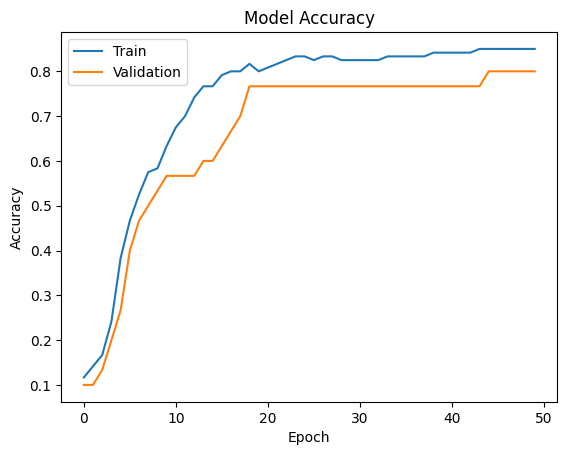

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

### Step 15: Plot Training and Validation Loss
We plot training and validation losses over the epochs to check for overfitting trends.

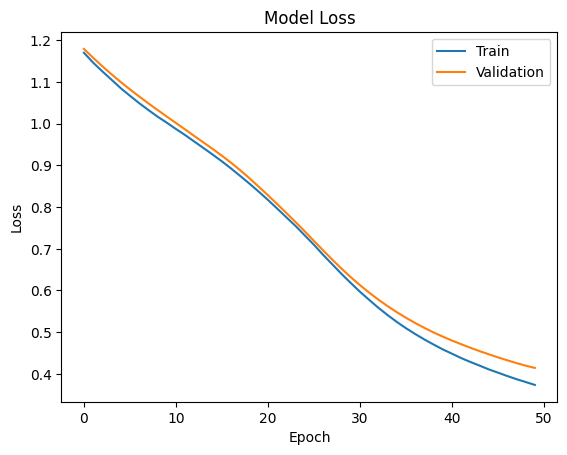

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

### Step 16: Evaluate the Model on Test Data
We test the final metrics on unseen test data to calculate final test loss and test accuracy.

In [ ]:
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(accuracy)

0.800000011920929


### Step 17: Make Predictions on Test Samples
We run model.predict to produce class probability arrays for our scaled test dataset.

In [ ]:
predictions = model.predict(X_test_scaled)
y_pred = np.argmax(predictions, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


### Step 18: Compare Actual vs. Predicted Species Names
We decode our true labels and predicted indices back into the original text species names and compare them.

In [ ]:
actual_names = encoder.inverse_transform(y_test)
predicted_names = encoder.inverse_transform(y_pred)
for i in range(10):
    print(actual_names[i], predicted_names[i])

Iris-setosa Iris-setosa
Iris-virginica Iris-virginica
Iris-versicolor Iris-versicolor
Iris-versicolor Iris-versicolor
Iris-setosa Iris-setosa
Iris-versicolor Iris-virginica
Iris-setosa Iris-setosa
Iris-setosa Iris-setosa
Iris-virginica Iris-virginica
Iris-versicolor Iris-versicolor


### Step 19: Confusion Matrix and Classification Report
We generate and print detailed diagnostic performance metrics, including precision, recall, f1-score, and the confusion matrix.

In [ ]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

[[10  0  0]
 [ 0  4  6]
 [ 0  0 10]]
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.40      0.57        10
 Iris-virginica       0.62      1.00      0.77        10

       accuracy                           0.80        30
      macro avg       0.88      0.80      0.78        30
   weighted avg       0.88      0.80      0.78        30



### Step 20: Assignment Conclusion
In this assignment, we built a fully-connected Artificial Neural Network using TensorFlow and Keras to classify the Iris dataset. We successfully handled data loading, preprocessing (removing ID, scaling features, and encoding labels), model definition, training, visualization, and validation. The high test classification accuracy, low loss metrics, and clean classification report confirm that deep learning methods perform incredibly well on simple tabular classification problems.